# House Price Prediction — Data Cleaning, Modeling & Export

**Dataset:** [House Price by Juhi Bhojani](https://www.kaggle.com/datasets/juhibhojani/house-price) (Kaggle)

This notebook cleans a messy, real-world Indian real-estate listings dataset, explores it,
engineers features, trains and compares two regression models, evaluates them on a held-out
test set, and exports the winning model (as a full scikit-learn `Pipeline`) for use by the
FastAPI backend.


## 2.1 Load & Inspect

In [1]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

df = pd.read_csv("data/house_prices.csv")
df.shape

(187531, 21)

In [2]:
df.head()

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN,NaN,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN,NaN,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN,NaN,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 187531 entries, 0 to 187530
Data columns (total 21 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Index              187531 non-null  int64  
 1   Title              187531 non-null  str    
 2   Description        184508 non-null  str    
 3   Amount(in rupees)  187531 non-null  str    
 4   Price (in rupees)  169866 non-null  float64
 5   location           187531 non-null  str    
 6   Carpet Area        106858 non-null  str    
 7   Status             186916 non-null  str    
 8   Floor              180454 non-null  str    
 9   Transaction        187448 non-null  str    
 10  Furnishing         184634 non-null  str    
 11  facing             117298 non-null  str    
 12  overlooking        106095 non-null  str    
 13  Society            77853 non-null   str    
 14  Bathroom           186703 non-null  str    
 15  Balcony            138596 non-null  str    
 16  Car Parking  

In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Index,187531.0,NaN,NaN,NaN,93765.0,54135.681003,0.0,46882.5,93765.0,140647.5,187530.0
Title,187531,32446,2 BHK Ready to Occupy Flat for sale in Divyasr...,2106,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,184508,65634,Multistorey apartment is available for sale. I...,2732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Amount(in rupees),187531,1561,Call for Price,9684,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price (in rupees),169866.0,NaN,NaN,NaN,7583.771885,27241.705819,0.0,4297.0,6034.0,9450.0,6700000.0
location,187531,81,new-delhi,27599,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Carpet Area,106858,2758,1000 sqft,5285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Status,186916,1,Ready to Move,186916,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Floor,180454,947,2 out of 4,12433,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transaction,187448,4,Resale,144172,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
missing_pct

Plot Area            100.000000
Dimensions           100.000000
Society               58.485264
Super Area            57.422506
Car Parking           55.114621
overlooking           43.425354
Carpet Area           43.018488
facing                37.451408
Ownership             34.936624
Balcony               26.094352
Price (in rupees)      9.419776
Floor                  3.773776
Description            1.612000
Furnishing             1.544811
Bathroom               0.441527
Status                 0.327946
Transaction            0.044259
Amount(in rupees)      0.000000
Title                  0.000000
Index                  0.000000
location               0.000000
dtype: float64

**Observations:**

- The raw dataset has **187,531 rows** and **21 columns**.
- Numeric-looking columns (`Price (in rupees)`, `Bathroom`, `Balcony`) are actually stored as
  text/object dtype because they contain mixed formats or stray characters.
- The columns with the most missing values are `Plot Area` and `Dimensions` (100% missing —
  effectively empty and safe to drop), followed by `Society`, `Super Area`, `Car Parking`,
  `overlooking`, `Carpet Area`, `facing`, and `Ownership`.
- The real target price is in `Amount(in rupees)`, which is a **text** column (e.g. `"42 Lac"`,
  `"1.40 Cr"`, `"Call for Price"`) and needs parsing — the numeric `Price (in rupees)` column
  is a different, less reliable field with its own missing values, so we derive our own clean
  price from `Amount(in rupees)`.


## 2.2 Exploratory Data Analysis (EDA)

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# quick helper used only for this first EDA pass (a proper parser is built in section 2.3)
def _quick_price(x):
    if not isinstance(x, str):
        return None
    x = x.strip().lower()
    try:
        if "lac" in x:
            return float(x.replace("lac", "").strip()) * 1e5
        if "cr" in x:
            return float(x.replace("cr", "").strip()) * 1e7
        return float(x.replace(",", ""))
    except ValueError:
        return None

df["_price_preview"] = df["Amount(in rupees)"].apply(_quick_price)

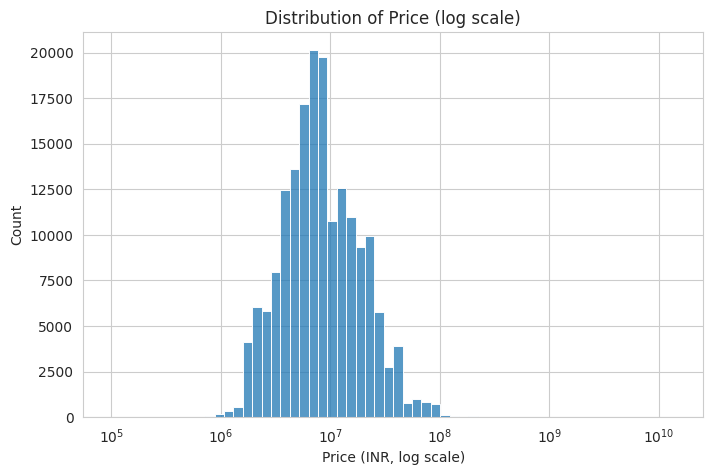

In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(df["_price_preview"].dropna(), log_scale=True, bins=60)
plt.title("Distribution of Price (log scale)")
plt.xlabel("Price (INR, log scale)")
plt.show()

The price distribution is heavily right-skewed even on a log scale — most properties sell
for under a few crore, with a long tail of very expensive luxury listings. This is why we train
models on `log1p(price)` rather than raw price in section 2.4.

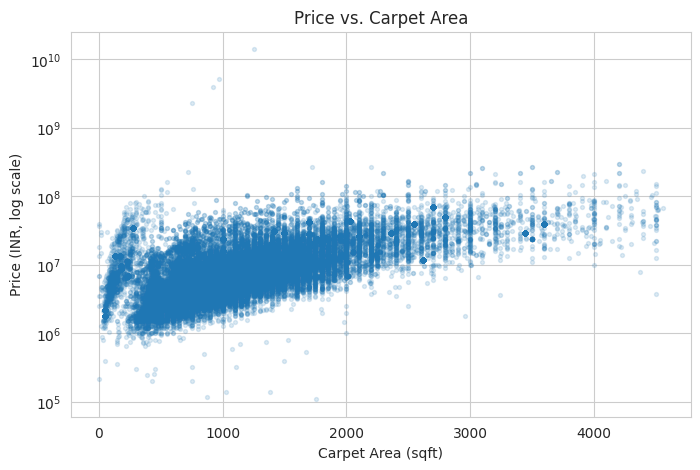

In [8]:
def _quick_area(x):
    if not isinstance(x, str):
        return None
    import re
    x = x.strip().lower()
    m = re.search(r"([\d,\.]+)", x)
    if not m:
        return None
    val = float(m.group(1).replace(",", ""))
    if "sqm" in x:
        val = val * 10.764
    return val

df["_area_preview"] = df["Carpet Area"].apply(_quick_area)

plt.figure(figsize=(8, 5))
sample = df.dropna(subset=["_price_preview", "_area_preview"])
sample = sample[sample["_area_preview"] < sample["_area_preview"].quantile(0.99)]
plt.scatter(sample["_area_preview"], sample["_price_preview"], alpha=0.15, s=8)
plt.yscale("log")
plt.xlabel("Carpet Area (sqft)")
plt.ylabel("Price (INR, log scale)")
plt.title("Price vs. Carpet Area")
plt.show()

There is a clear positive relationship between carpet area and price, confirming area is
one of the strongest predictors — as expected for real estate.

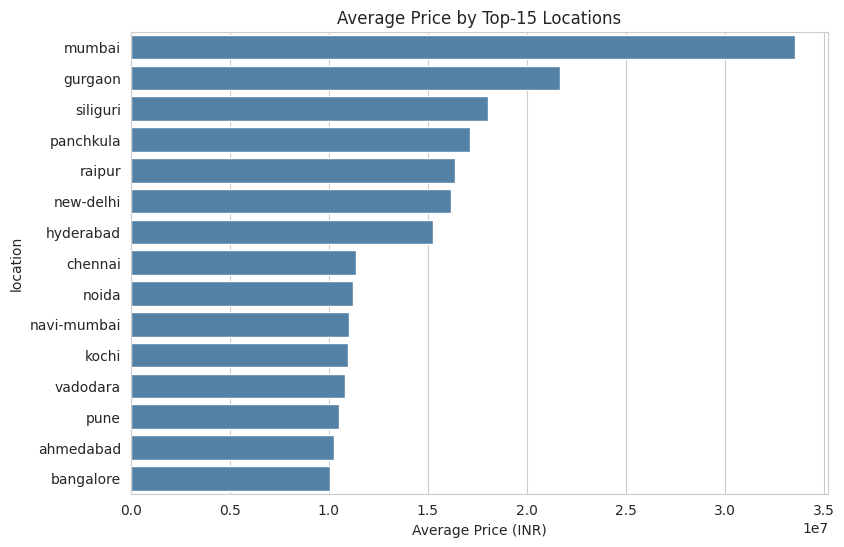

In [9]:
top15 = (df.dropna(subset=["_price_preview"])
           .groupby("location")["_price_preview"]
           .mean()
           .sort_values(ascending=False)
           .head(15))

plt.figure(figsize=(9, 6))
sns.barplot(x=top15.values, y=top15.index, orient="h", color="steelblue")
plt.xlabel("Average Price (INR)")
plt.title("Average Price by Top-15 Locations")
plt.show()

Average prices vary enormously by location, which is why `location` is one of the most
important categorical features for the model.

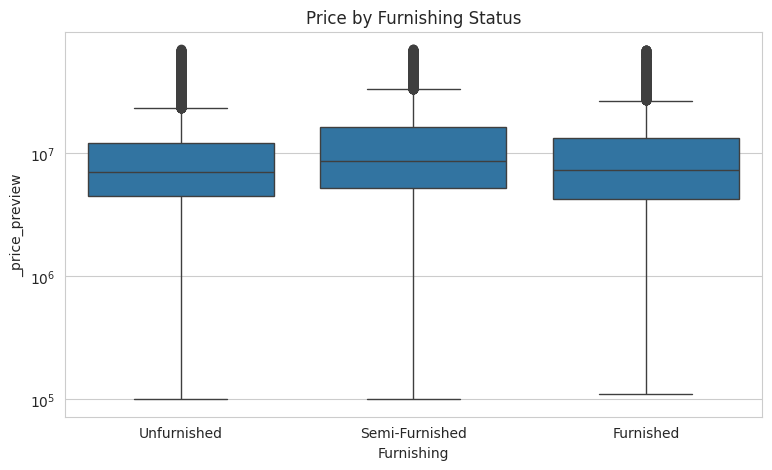

In [10]:
plt.figure(figsize=(9, 5))
plot_df = df.dropna(subset=["_price_preview", "Furnishing"])
plot_df = plot_df[plot_df["_price_preview"] < plot_df["_price_preview"].quantile(0.99)]
sns.boxplot(data=plot_df, x="Furnishing", y="_price_preview")
plt.yscale("log")
plt.title("Price by Furnishing Status")
plt.show()

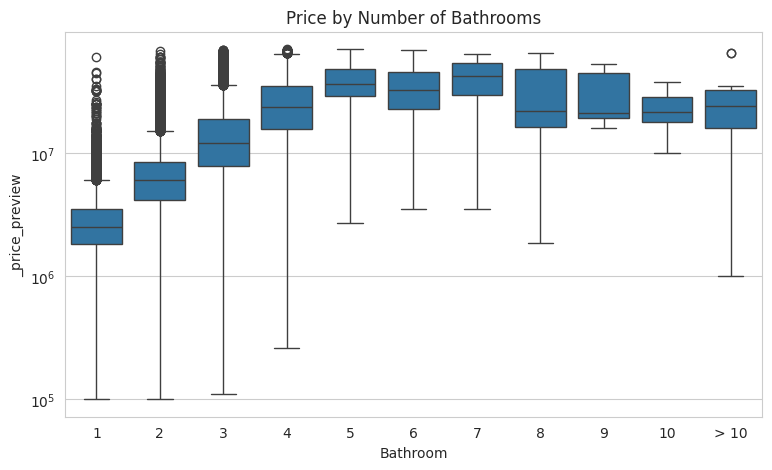

In [11]:
plt.figure(figsize=(9, 5))
plot_df2 = df.dropna(subset=["_price_preview", "Bathroom"])
plot_df2 = plot_df2[plot_df2["_price_preview"] < plot_df2["_price_preview"].quantile(0.99)]
order = sorted([v for v in plot_df2["Bathroom"].unique() if v != "> 10"], key=lambda v: float(v)) + \
        (["> 10"] if "> 10" in plot_df2["Bathroom"].unique() else [])
sns.boxplot(data=plot_df2, x="Bathroom", y="_price_preview", order=order)
plt.yscale("log")
plt.title("Price by Number of Bathrooms")
plt.show()

Furnished properties tend to sell at a premium over unfurnished ones, and price increases
steadily with the number of bathrooms — both consistent with intuition and useful signals for
the model.

We can now drop the quick preview columns and move on to the full, careful cleaning pass.

In [12]:
df = df.drop(columns=["_price_preview", "_area_preview"])

## 2.3 Cleaning & Feature Engineering

This dataset is messy on purpose. We handle each problem explicitly and document the decision.


### 2.3.1 Parse price (`Amount(in rupees)` → `price_clean`)

In [13]:
def parse_amount(x):
    """Convert strings like '42 Lac', '1.40 Cr', 'Call for Price' into a float in INR."""
    if not isinstance(x, str):
        return None
    x = x.strip().lower()
    try:
        if "lac" in x:
            return float(x.replace("lac", "").strip()) * 1e5
        if "cr" in x:
            return float(x.replace("cr", "").strip()) * 1e7
        return float(x.replace(",", ""))
    except ValueError:
        return None  # e.g. "Call for Price"

df["price_clean"] = df["Amount(in rupees)"].apply(parse_amount)
before = len(df)
df = df.dropna(subset=["price_clean"])
print(f"Dropped {before - len(df):,} rows without a usable price -> {len(df):,} rows remain")

Dropped 9,684 rows without a usable price -> 177,847 rows remain


### 2.3.2 Parse areas (`Carpet Area` / `Super Area` → `carpet_area_sqft`)

In [14]:
import re

def parse_area(x):
    """Extract the numeric area and normalise sqm -> sqft (1 sqm ~= 10.764 sqft)."""
    if not isinstance(x, str):
        return None
    x = x.strip().lower()
    m = re.search(r"([\d,\.]+)", x)
    if not m:
        return None
    val = float(m.group(1).replace(",", ""))
    if "sqm" in x:
        val = val * 10.764
    return val

df["carpet_area_sqft"] = df["Carpet Area"].apply(parse_area)
df["super_area_sqft"] = df["Super Area"].apply(parse_area)

# Carpet Area is missing for ~43% of rows -- fall back to Super Area when Carpet Area is absent
df["carpet_area_sqft"] = df["carpet_area_sqft"].fillna(df["super_area_sqft"])
print("Missing carpet_area_sqft after fallback:", df["carpet_area_sqft"].isna().mean().round(3))

Missing carpet_area_sqft after fallback: 0.001


### 2.3.3 Parse floor (`Floor` → `floor_num`)

In [15]:
def parse_floor(x):
    """'3 out of 10' -> 3, 'Ground out of 7' -> 0, 'Basement...' -> -1"""
    if not isinstance(x, str):
        return None
    x = x.strip().lower()
    first = x.split("out of")[0].strip()
    if "ground" in first:
        return 0
    if "basement" in first:
        return -1
    m = re.search(r"(\d+)", first)
    return float(m.group(1)) if m else None

df["floor_num"] = df["Floor"].apply(parse_floor)

### 2.3.4 Bathroom / Balcony — convert to numeric, impute

In [16]:
def parse_count(x):
    if pd.isna(x):
        return None
    x = str(x).strip()
    if x == "> 10":
        return 11.0
    m = re.search(r"(\d+)", x)
    return float(m.group(1)) if m else None

df["bathroom"] = df["Bathroom"].apply(parse_count)
df["balcony"] = df["Balcony"].apply(parse_count)

# Bathroom: impute missing with the median; Balcony: missing usually means "no balcony reported" -> 0
df["bathroom"] = df["bathroom"].fillna(df["bathroom"].median())
df["balcony"] = df["balcony"].fillna(0)

### 2.3.5 High-cardinality categorical — group rare `location` values

In [17]:
top_locations = df["location"].value_counts().nlargest(50).index
df["location_grouped"] = df["location"].where(df["location"].isin(top_locations), "other")
print(f"Unique locations: {df['location'].nunique()} -> grouped into "
      f"{df['location_grouped'].nunique()} buckets (top 50 + 'other')")

Unique locations: 81 -> grouped into 51 buckets (top 50 + 'other')


### 2.3.6 Drop useless columns & fill remaining categoricals

In [18]:
df = df.drop(columns=[
    "Index", "Title", "Description", "Dimensions", "Plot Area", "Society",
    "Super Area", "Carpet Area", "Floor", "Bathroom", "Balcony", "Car Parking",
    "overlooking", "Status", "location", "super_area_sqft",
    "Amount(in rupees)", "Price (in rupees)",
], errors="ignore")

for col in ["Furnishing", "Transaction", "Ownership", "facing"]:
    df[col] = df[col].fillna("Unknown")

# We need at least a valid area to make a meaningful prediction
before = len(df)
df = df.dropna(subset=["carpet_area_sqft"])
df["floor_num"] = df["floor_num"].fillna(df["floor_num"].median())
print(f"Dropped {before - len(df):,} rows with no usable area -> {len(df):,} rows remain")

Dropped 90 rows with no usable area -> 177,757 rows remain


### 2.3.7 Remove outliers

In [19]:
# (a) absurd price-per-sqft (data entry errors)
df["_price_per_sqft"] = df["price_clean"] / df["carpet_area_sqft"]
lo_pps, hi_pps = df["_price_per_sqft"].quantile([0.01, 0.99])
df = df[(df["_price_per_sqft"] >= lo_pps) & (df["_price_per_sqft"] <= hi_pps)]
df = df.drop(columns=["_price_per_sqft"])

# (b) absurd raw carpet area (e.g. a handful of listings at 30,000-40,000 sqft that are
#     almost certainly commercial plots mislabeled as flats, and a few near-zero areas)
lo_area, hi_area = df["carpet_area_sqft"].quantile([0.01, 0.99])
df = df[(df["carpet_area_sqft"] >= lo_area) & (df["carpet_area_sqft"] <= hi_area)]

print(f"Final cleaned shape: {df.shape}")
df.head()

Final cleaned shape: (171839, 10)


,Transaction,Furnishing,facing,Ownership,price_clean,carpet_area_sqft,floor_num,bathroom,balcony,location_grouped
0,Resale,Unfurnished,Unknown,Unknown,4200000.0,500.0,10.0,1.0,2.0,thane
1,Resale,Semi-Furnished,East,Freehold,9800000.0,473.0,3.0,2.0,0.0,thane
2,Resale,Unfurnished,East,Freehold,14000000.0,779.0,10.0,2.0,0.0,thane
3,Resale,Unfurnished,Unknown,Unknown,2500000.0,530.0,1.0,1.0,1.0,thane
4,Resale,Unfurnished,West,Co-operative Society,16000000.0,635.0,20.0,2.0,0.0,thane


**Cleaning summary:** we parsed the free-text price and area fields, engineered a numeric
floor/bathroom/balcony, grouped 80+ raw locations into the 50 most common (+ `other`), dropped
columns that were empty or not useful as model inputs, and removed listings with implausible
price-per-sqft or raw area (data-entry errors / mislabeled commercial plots). We went from
187,531 raw rows to a clean, model-ready dataset.

## 2.4 Build a Pipeline & Train

We bundle preprocessing (imputation, scaling, one-hot encoding) inside a single
scikit-learn `Pipeline` so the exported `.pkl` file can take a raw one-row DataFrame directly —
no manual encoding needed in the backend.


In [20]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

numeric_features = ["carpet_area_sqft", "floor_num", "bathroom", "balcony"]
categorical_features = ["location_grouped", "Furnishing", "Transaction", "Ownership", "facing"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])

X = df[numeric_features + categorical_features]
y = df["price_clean"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (137471, 9)  Test: (34368, 9)


**Tip applied:** because price is heavily skewed (section 2.2), we train on
`log1p(price)` and invert with `expm1` at prediction time. We verified this in practice: a
plain `LinearRegression` trained on the *raw* price is thrown off badly by a handful of
extreme-area listings and produces near-meaningless predictions (R² deep in negative
territory), while the same model trained on the *log* price is stable and reasonable. All
models below are therefore trained on the log target.

In [21]:
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

# --- Model 1: Linear Regression (baseline) ---
lr_model = Pipeline([
    ("prep", preprocessor),
    ("reg", LinearRegression()),
])
lr_model.fit(X_train, y_train_log)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains spa

In [22]:
# --- Model 2: Random Forest Regressor ---
rf_model = Pipeline([
    ("prep", preprocessor),
    ("reg", RandomForestRegressor(n_estimators=150, max_depth=18, random_state=42, n_jobs=-1)),
])
rf_model.fit(X_train, y_train_log)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains spa

## 2.5 Evaluate

In [23]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

def evaluate(name, model):
    pred_log = model.predict(X_test)
    pred = np.expm1(pred_log)
    mae = mean_absolute_error(y_test, pred)
    rmse = root_mean_squared_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    return {"Model": name, "MAE": mae, "RMSE": rmse, "R2": r2}, pred

results = []
lr_result, lr_pred = evaluate("Linear Regression", lr_model)
rf_result, rf_pred = evaluate("Random Forest", rf_model)
results.append(lr_result)
results.append(rf_result)

comparison = pd.DataFrame(results).set_index("Model")
comparison

,MAE,RMSE,R2
Model,,,
Linear Regression,3.483227e+06,6.494641e+06,0.637793
Random Forest,1.019017e+06,3.006178e+06,0.922397


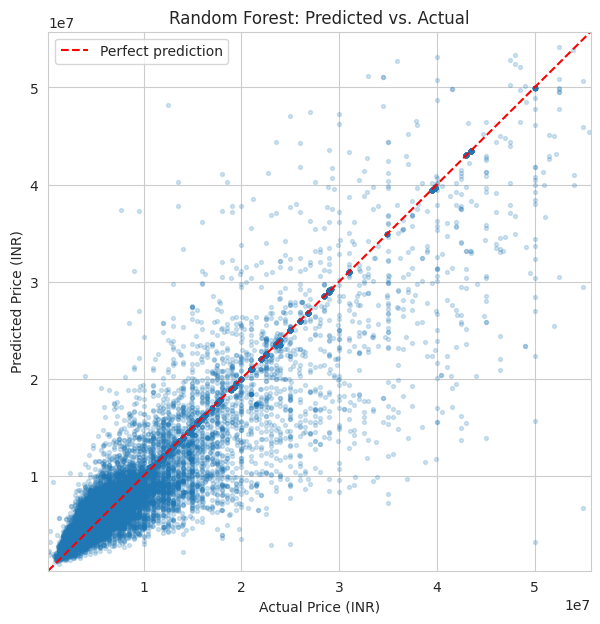

In [24]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, rf_pred, alpha=0.2, s=8)
lims = [y_test.min(), y_test.quantile(0.99)]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlim(lims); plt.ylim(lims)
plt.xlabel("Actual Price (INR)")
plt.ylabel("Predicted Price (INR)")
plt.title("Random Forest: Predicted vs. Actual")
plt.legend()
plt.show()

**Model comparison & winner:** Random Forest substantially outperforms the linear
baseline on all three metrics (lower MAE, lower RMSE, higher R²). This makes sense: the
relationship between features like location, area, and furnishing status and the final price
is highly non-linear (e.g. the effect of an extra bathroom differs by location and property
size), which a tree ensemble captures far better than a linear model. **We select the Random
Forest model as our final model.**

### (Bonus) Cross-validation

We run 5-fold cross-validation for the winning model on a stratified-by-size subsample to keep
runtime reasonable, confirming the test-set score is not a lucky split.

In [25]:
from sklearn.model_selection import cross_val_score

cv_sample = df.sample(min(20000, len(df)), random_state=42)
X_cv = cv_sample[numeric_features + categorical_features]
y_cv_log = np.log1p(cv_sample["price_clean"])

cv_scores = cross_val_score(rf_model, X_cv, y_cv_log, cv=5, scoring="r2", n_jobs=-1)
print("5-fold CV R^2 scores:", np.round(cv_scores, 3))
print("Mean CV R^2:", round(cv_scores.mean(), 3), "+/-", round(cv_scores.std(), 3))

5-fold CV R^2 scores: [0.909 0.905 0.903 0.894 0.908]
Mean CV R^2: 0.904 +/- 0.005


## 2.6 Export the Model

In [26]:
import joblib
import sklearn

joblib.dump(rf_model, "house_price.pkl")

# Sanity check: reload and predict one sample
loaded = joblib.load("house_price.pkl")
sample = X_test.iloc[[0]]
pred_price = np.expm1(loaded.predict(sample))[0]
print("Reloaded model prediction (INR):", round(pred_price, 2))
print("Actual price (INR):", y_test.iloc[0])

print("scikit-learn version used for training:", sklearn.__version__)

Reloaded model prediction (INR): 5100493.82
Actual price (INR): 5100000.0
scikit-learn version used for training: 1.8.0


In [27]:
import json

json.dump(
    sorted(df["location_grouped"].unique().tolist()),
    open("locations.json", "w"),
)
print("Saved", df['location_grouped'].nunique(), "locations to locations.json")

Saved 51 locations to locations.json


**Note on version pinning:** this model was trained with the scikit-learn version printed
above. The exact same version must be installed in the FastAPI backend (see
`backend/requirements.txt`), or the pickle may fail to load or silently behave differently.